# Etapa 5. Índice multidimensional y KNN exacto (KD-Tree)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 3, 4 y 5: Carlos.

## Función de la etapa en el pipeline

La etapa 5 resuelve las consultas sobre **varios atributos a la vez**. El escenario B pide generar productos similares a partir de sus atributos. El B+Tree de la etapa 4 ordena por una sola clave y no puede responder "los 10 productos más parecidos a este en precio, calificación y popularidad". Para eso cada producto se representa como un punto en un espacio de 4 dimensiones y se buscan sus k vecinos más cercanos (KNN).

La estructura es un **KD-Tree** implementado a mano. Responde dos tipos de consulta.

- **KNN exacto.** Los k productos más cercanos a uno dado, con un filtro opcional por categoría.
- **Rango multidimensional.** Los productos dentro de una caja, por ejemplo precio entre 10 y 20 dólares, calificación de al menos 4.5 y al menos 1 000 calificaciones.

El **KNN por fuerza bruta**, que calcula la distancia a todos los puntos, es la línea base exacta. La etapa 7 trabaja con vectores de dimensión alta, donde el KD-Tree pierde la poda (experimento B), y usará esta fuerza bruta como referencia exacta para medir el recall@K de su búsqueda aproximada. El código de la etapa está en `src/etapa_5/kdtree.py`; el notebook lo importa y muestra cada parte junto a su explicación.

**KD-Tree o R-Tree.** El enunciado permite cualquiera de los dos según el escenario. Se elige el KD-Tree por tres razones.

- Los datos son **puntos**. El R-Tree está pensado para objetos con extensión, como rectángulos o polígonos, y agrupa sus cajas envolventes (Guttman, 1984).
- La dimensión es **baja** (d = 4), que es donde el KD-Tree poda bien (Friedman, Bentley y Finkel, 1977).
- El conjunto es **casi estático**. Se construye una vez desde el catálogo y recibe pocas inserciones. El R-Tree se justifica cuando las inserciones son frecuentes.

Los árboles métricos, como el VP-Tree o el M-Tree, sirven para cualquier métrica, pero con distancia euclidiana y dimensión baja no podan más que el KD-Tree y cada corte cuesta más, porque compara distancias en lugar de una coordenada.

## Proceso

```
índice de precios (etapa 4) + catálogo en disco (etapa 3) + estado del stream (etapa 3)
   │
   ├─ 1. recorrer el B+Tree y leer el registro de cada producto con precio
   ├─ 2. construir el vector de 4 atributos y normalizarlo (z-score)
   ├─ 3. construir el KD-Tree: mediana de la dimensión de mayor dispersión   O(n log n)
   │
   ├─ KNN: descenso al lado de q, poda por distancia al hiperplano        ≈ O(log n) en dimensión baja
   └─ rango: descenso por los lados que cortan la caja
   │
vectores y vecinos exactos (etapa 9)
```

## Pasos del notebook

1. Configuración y entrada.
2. Vectores de productos.
3. KD-Tree propio.
4. Construcción del índice.
5. Consultas de productos similares y por rango.
6. Experimentos de complejidad.
7. Salida de la etapa 5.

## Paso 1. Configuración y entrada

La etapa usa tres salidas de las etapas anteriores.

- `data/interim/<CATEGORIA>/etapa_4/indice_precio.bpt`, el índice de los productos con precio. Recorrer sus hojas enlazadas da los productos en orden de precio y la posición de cada registro.
- `data/interim/<CATEGORIA>/etapa_3/catalogo.jsonl`, el catálogo en disco, del que se leen la calificación, el número de calificaciones y la categoría.
- `data/interim/<CATEGORIA>/etapa_3/estado_productos.parquet`, la actividad de cada producto en el stream.

La salida de la etapa se guarda en `data/interim/<CATEGORIA>/etapa_5/` y los resultados de los experimentos en `results/etapa_5/`. La celda muestra al final la plataforma y la semilla, que el enunciado pide reportar junto con los tiempos.

Los experimentos del paso 6 guardan sus resultados en `results/etapa_5/` y se reutilizan si existen. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`. Cada archivo de resultados guarda el procesador y la versión de Python con que se midió, y las figuras muestran esa plataforma aunque el notebook se ejecute en otra máquina.

In [1]:
import gc
import inspect
import math
import platform
import sys
import time
import tracemalloc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pyarrow as pa
import pyarrow.parquet as pq

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.etapa_3.storage import RUTA_ESTADOS
from src.etapa_4.bplustree import RUTA_INDICE_PRECIO, ArbolBMas
from src.etapa_5.kdtree import (ATRIBUTOS, CARPETA_ETAPA5, RUTA_VECINOS, RUTA_VECTORES, TAM_HOJA, IndiceProductos,
                                KDTree, construir_vectores, knn_fuerza_bruta)

SEED = config.SEED
CATEGORIA = config.CATEGORIA
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS / "etapa_5"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
CARPETA_ETAPA5.mkdir(parents=True, exist_ok=True)
assert RUTA_INDICE_PRECIO.exists(), "Falta la salida de la etapa 4. Ejecutar antes notebooks/etapa4_indexacion_bplustree.ipynb"
assert RUTA_ESTADOS.exists(), "Falta la salida de la etapa 3. Ejecutar antes notebooks/etapa3_almacenamiento_cache.ipynb"

# Las mediciones guardadas en results/etapa_5/ se reutilizan. Con True se miden de nuevo.
REEJECUTAR_EXPERIMENTOS = False

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor() or platform.machine(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}


def ruta_relativa(ruta):
    return ruta.relative_to(RAIZ).as_posix()


def resultados(ruta, medir_tabla):
    """Lee la tabla de resultados si existe. Si no, la mide con medir_tabla() y la guarda.

    Cada tabla guarda el procesador y la versión de Python con que se midió.
    """
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        print(f"Resultados leídos de {ruta_relativa(ruta)}")
        return pd.read_csv(ruta, dtype={"procesador": str, "python": str})
    tabla = medir_tabla().assign(procesador=PLATAFORMA["procesador"], python=PLATAFORMA["python"])
    tabla.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta_relativa(ruta)}")
    return tabla


def plataforma_de(tabla):
    """Procesador y versión de Python con que se midió una tabla de resultados."""
    return f"{tabla['procesador'].iloc[0]}, Python {tabla['python'].iloc[0]}"


print(f"Categoría: {CATEGORIA}")
PLATAFORMA

Categoría: Office_Products


{'sistema': 'Windows-10-10.0.19045-SP0',
 'procesador': 'AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD',
 'nucleos': 8,
 'ram_gb': 32.1,
 'python': '3.12.0',
 'semilla': 42}

## Paso 2. Vectores de productos

Cada producto del índice de precios se representa con cuatro atributos.

| Atributo | Definición | Justificación |
| --- | --- | --- |
| `log_precio` | log(1 + precio) | Los precios tienen una cola larga (la celda imprime su rango). En escala logarítmica, 10 y 20 dólares están tan lejos como 100 y 200 |
| `average_rating` | Calificación promedio del catálogo, de 1 a 5 | Calidad percibida |
| `log_rating_number` | log(1 + número de calificaciones) | Popularidad histórica. La distribución tiene una cola larga |
| `log_actividad_stream` | log(1 + vistas + carritos + compras en el stream) | Popularidad reciente, registrada por la etapa 3 |

Cada atributo se normaliza con z-score (media 0 y desviación 1). Sin esa normalización, el atributo con mayor desviación dominaría la distancia euclidiana. La tabla de la celda muestra que la desviación de `log_rating_number` es casi el triple que la de `average_rating`.

La categoría de último nivel no entra en el vector porque no es numérica. Se usa como filtro, para buscar productos similares dentro de la misma categoría.

La celda también separa dos conteos de productos activos. Uno cuenta los productos del índice con vistas, carritos o compras en el stream, que son los que tienen `log_actividad_stream` mayor que 0. El otro cuenta los productos del índice que tienen estado en la etapa 3, que incluye a los que solo recibieron reseñas o devoluciones. El paso 7 calcula los vecinos de este segundo grupo.

In [2]:
t0 = time.perf_counter()
asins, X_crudo, categorias, titulos = construir_vectores()
t_vectores = time.perf_counter() - t0

estados = pq.read_table(RUTA_ESTADOS).to_pandas()
en_indice = set(asins)
con_estado = estados[estados["parent_asin"].isin(en_indice)]
solo_resenas_o_devoluciones = int(((con_estado["vistas"] + con_estado["carritos"] + con_estado["compras"]) == 0).sum())

print(f"Vectores: {len(asins):,} productos × {X_crudo.shape[1]} atributos en {t_vectores:.1f} s")
print(f"Categorías de último nivel: {len(set(categorias)):,}")
print(f"Precio: de {math.expm1(X_crudo[:, 0].min()):,.2f} a {math.expm1(X_crudo[:, 0].max()):,.2f} dólares")
print(f"Productos con vistas, carritos o compras en el stream: {(X_crudo[:, 3] > 0).sum():,}")
print(f"Productos con estado en la etapa 3: {len(con_estado):,} "
      f"({solo_resenas_o_devoluciones:,} solo con reseñas o devoluciones)")
pd.DataFrame(X_crudo, columns=ATRIBUTOS).describe().round(3)

Vectores: 336,415 productos × 4 atributos en 11.7 s
Categorías de último nivel: 607
Precio: de 0.01 a 30,499.00 dólares
Productos con vistas, carritos o compras en el stream: 193,416
Productos con estado en la etapa 3: 193,422 (6 solo con reseñas o devoluciones)


,log_precio,average_rating,log_rating_number,log_actividad_stream
count,336415.000,336415.000,336415.000,336415.000
mean,3.171,4.325,3.490,1.547
std,0.959,0.672,1.867,1.578
min,0.010,1.000,0.693,0.000
25%,2.441,4.100,1.946,0.000
50%,2.993,4.500,3.332,1.609
75%,3.761,4.700,4.745,2.565
max,10.325,5.000,12.284,9.313


## Paso 3. KD-Tree propio

Un KD-Tree es un árbol binario de búsqueda sobre puntos de d dimensiones (Bentley, 1975). Cada nodo interno divide su región en dos con un hiperplano perpendicular a una dimensión.

- **Dimensión de corte.** Se elige la de mayor dispersión dentro del nodo. Así las regiones quedan más cercanas a cubos que si se alternaran las dimensiones en orden fijo.
- **Valor de corte.** La mediana, obtenida con `np.argpartition` en O(m) para m puntos. Cada división deja dos mitades iguales, así que el árbol queda balanceado con altura log₂(n / tamaño de hoja). La construcción cuesta O(n log n).
- **Hojas.** Guardan hasta 32 puntos. Los puntos se reordenan para que cada hoja ocupe un tramo contiguo de un arreglo, y la distancia de la consulta a todos los puntos de una hoja se calcula con una operación de numpy.

**Búsqueda KNN.** Es un recorrido en profundidad que entra primero al lado del hiperplano donde está la consulta q. Los k mejores candidatos se guardan en el `MinHeap` de la etapa 2 con la distancia negada, así que la raíz del heap es el peor candidato y se consulta en O(1). Un subárbol se descarta si la distancia de q a su región ya no mejora al peor candidato. Con dimensión baja se visitan O(log n) nodos en promedio. El peor caso es O(n), cuando la poda no descarta nada, y eso ocurre cuando la dimensión es alta.

**Rango.** Desciende solo por los hijos cuya región corta la caja y filtra los puntos de cada hoja con numpy.

**Filtro por categoría.** En las hojas solo se aceptan puntos con la etiqueta pedida. La poda sigue siendo correcta, porque la cota de distancia no depende de la etiqueta.

**KD-Tree por categoría.** Con el filtro sobre el árbol global, los productos de una categoría pequeña están dispersos en todo el espacio y la búsqueda recorre muchas hojas hasta reunir k productos de esa categoría. Por eso `IndiceProductos` construye además un KD-Tree con los productos de cada una de las categorías. La consulta de productos similares dentro de la categoría usa ese árbol, que solo contiene sus productos. El filtro sobre el árbol global se mantiene para comparar los dos métodos en el experimento D. La construcción de todos los árboles por categoría cuesta O(n log n) en total, igual que la del árbol global.

In [3]:
print(inspect.getsource(KDTree._construir))
print(inspect.getsource(KDTree.knn))
print(inspect.getsource(KDTree.rango))

    def _construir(self, lo, hi):
        nodo = len(self.dim)
        for lista in (self.dim, self.corte, self.izq, self.der, self.lo, self.hi):
            lista.append(-1)
        self.lo[nodo], self.hi[nodo] = lo, hi
        if hi - lo <= self.tam_hoja:
            return nodo                                # hoja: dim = -1
        indices = self.perm[lo:hi]
        puntos = self._X0[indices]
        dim = int(np.argmax(puntos.max(axis=0) - puntos.min(axis=0)))
        if puntos[:, dim].max() == puntos[:, dim].min():
            return nodo                                # todos los puntos son iguales: hoja grande
        mitad = (hi - lo) // 2
        orden = np.argpartition(puntos[:, dim], mitad)
        self.perm[lo:hi] = indices[orden]
        # La mitad izquierda queda con valores <= corte y la derecha con valores >= corte
        self.dim[nodo] = dim
        self.corte[nodo] = float(puntos[orden[mitad], dim])
        self.izq[nodo] = self._construir(lo, lo + mitad)
        se

## Paso 4. Construcción del índice

`IndiceProductos` normaliza los vectores y construye el KD-Tree global y un KD-Tree por categoría. La construcción del índice real se mide una vez, porque es la operación de la etapa sobre el catálogo completo; las mediciones con repeticiones están en el paso 6. Su memoria actual y pico se mide con `tracemalloc` en una segunda construcción.

In [4]:
t0 = time.perf_counter()
indice = IndiceProductos(asins, X_crudo, categorias)
t_kd = time.perf_counter() - t0
kd = indice.kd

gc.collect()
tracemalloc.start()
indice_medido = IndiceProductos(asins, X_crudo, categorias)
actual_indice, pico_indice = tracemalloc.get_traced_memory()
tracemalloc.stop()
del indice_medido

print(f"Índice construido en {t_kd:.2f} s: KD-Tree global con {kd.n_nodos:,} nodos y altura {kd.altura()} "
      f"(log₂(n / {TAM_HOJA}) = {math.log2(kd.n / TAM_HOJA):.1f}), y {len(indice.kd_categoria):,} árboles por categoría")
print(f"Memoria del índice: actual {actual_indice / 1e6:.1f} MB, pico {pico_indice / 1e6:.1f} MB "
      f"({actual_indice / kd.n:.0f} bytes por producto)")
print(f"Media de los atributos: {np.round(indice.media, 3).tolist()}")
print(f"Desviación de los atributos: {np.round(indice.desv, 3).tolist()}")

Índice construido en 2.83 s: KD-Tree global con 32,737 nodos y altura 15 (log₂(n / 32) = 13.4), y 607 árboles por categoría
Memoria del índice: actual 70.9 MB, pico 71.2 MB (211 bytes por producto)
Media de los atributos: [3.171, 4.325, 3.49, 1.547]
Desviación de los atributos: [0.959, 0.672, 1.867, 1.578]


## Paso 5. Consultas de productos similares y por rango

**Productos similares.** Se buscan los 5 vecinos más cercanos de uno de los productos más comprados en el stream, primero dentro de su categoría y después en todo el catálogo. Se reportan los puntos evaluados, que no dependen de la máquina; los tiempos se miden con repeticiones en el experimento D.

In [5]:
mas_comprado = estados.nlargest(10, "compras")["parent_asin"]
asin_ejemplo = next(a for a in mas_comprado if indice.posicion.obtener(a) is not None)


def tabla_vecinos(resultado):
    filas = []
    for distancia, a in resultado:
        j = indice.posicion.obtener(a)
        filas.append({"distancia": round(distancia, 3), "parent_asin": a, "categoria": categorias[j],
                      "precio": round(math.expm1(X_crudo[j, 0]), 2), "average_rating": X_crudo[j, 1],
                      "rating_number": int(round(math.expm1(X_crudo[j, 2]))), "title": titulos[j][:55]})
    return pd.DataFrame(filas)


i = indice.posicion.obtener(asin_ejemplo)
print(f"Producto: {asin_ejemplo}, {titulos[i][:70]}")
print(f"Categoría: {categorias[i]}, precio {math.expm1(X_crudo[i, 0]):.2f}, rating {X_crudo[i, 1]}, "
      f"{math.expm1(X_crudo[i, 2]):,.0f} calificaciones")
misma = indice.similares(asin_ejemplo, k=5, misma_categoria=True)
kd_c = indice.kd_categoria[int(indice.categoria[i])]
print(f"\nMisma categoría: {kd_c.puntos_evaluados:,} puntos evaluados de los {kd_c.n:,} de la categoría")
display(tabla_vecinos(misma))
todas = indice.similares(asin_ejemplo, k=5, misma_categoria=False)
print(f"Todo el catálogo: {kd.puntos_evaluados:,} puntos evaluados de {kd.n:,}")
display(tabla_vecinos(todas))

Producto: B0BN478RWJ, HP DeskJet 2755e Wireless Color All-in-One Printer with bonus 6 months
Categoría: Inkjet Printers, precio 59.99, rating 4.1, 31,419 calificaciones

Misma categoría: 181 puntos evaluados de los 321 de la categoría


,distancia,parent_asin,categoria,precio,average_rating,rating_number,title
0,0.984,B0BN49WKQ6,Inkjet Printers,99.89,4.1,18791,HP DeskJet 4155e Wireless Color All-in-One Pri...
1,1.221,B0CB76Q6QJ,Inkjet Printers,71.99,4.1,8991,HP Envy 6055e Wireless Color All-in-One Printe...
2,1.673,B08WCDLKFK,Inkjet Printers,169.99,4.2,9094,HP OfficeJet Pro 8025e Wireless Color All-in-O...
3,2.181,B0CB7BNHJG,Inkjet Printers,229.99,4.2,5040,HP OfficeJet Pro 9015e Wireless Color All-in-O...
4,2.193,B08WC7YQM3,Inkjet Printers,51.05,4.2,2387,HP OfficeJet Pro 8035e Wireless Color All-in-O...


Todo el catálogo: 315 puntos evaluados de 336,415


,distancia,parent_asin,categoria,precio,average_rating,rating_number,title
0,0.715,B01168IEJI,Ink Tank Printers,69.00,4.1,22571,Canon PIXMA MG3620 Wireless All-In-One Color I...
1,0.729,B0BLBTZDSN,Shredders,44.99,4.4,39373,"Bonsaii 6-Sheet Micro-Cut Paper Shredder, P-4 ..."
2,0.802,B09K4LZCY2,Label Makers,46.29,4.2,37433,DYMO Organizer Xpress Handheld Embossing Label...
3,0.904,B0BM61RCJQ,Back & Seat Cushions,47.99,4.4,96511,Everlasting Comfort Car Seat Cushion for Tailb...
4,0.950,B09R29K4K7,Landline Phones,43.95,4.3,22729,AT&T BL102 DECT 6.0 Cordless Phone for Home wi...


Sin el filtro, los vecinos pueden ser de cualquier categoría, porque solo se parecen en precio, calificación y popularidad. Para recomendar productos relacionados se usa el filtro por categoría.

**Verificación contra la fuerza bruta.** Para 1 000 productos al azar se comparan las distancias de los 10 vecinos con las de la fuerza bruta en tres casos, sin filtro, con el filtro sobre el árbol global y con el árbol de la categoría. Deben coincidir exactamente, porque los tres métodos son exactos.

In [6]:
rng = np.random.default_rng(SEED)
muestra = rng.choice(kd.n, size=1_000, replace=False)
diferentes = 0
for i in muestra:
    c = int(indice.categoria[i])
    for etiqueta in (None, c):
        a = [round(d, 9) for d, _ in kd.knn(indice.Z[i], 10, etiqueta=etiqueta)]
        b = [round(d, 9) for d, _ in knn_fuerza_bruta(indice.Z, indice.Z[i], 10, indice.categoria, etiqueta)]
        diferentes += a != b
    a = [round(d, 9) for d, _ in indice.kd_categoria[c].knn(indice.Z[i], 10)]
    diferentes += a != b
print(f"Consultas con resultados distintos: {diferentes} de {3 * len(muestra):,}")
assert diferentes == 0

Consultas con resultados distintos: 0 de 3,000


**Rango multidimensional.** Se buscan los productos con precio entre 10 y 20 dólares, calificación de al menos 4.5 y al menos 1 000 calificaciones. Los límites se transforman y normalizan igual que los vectores. La actividad en el stream no se restringe. El resultado se compara con la etapa 4. El B+Tree devuelve el rango de precio y los otros dos atributos se filtran después. El tiempo de las dos consultas se compara en el experimento D.

In [7]:
INFINITO = 1e9
MINIMOS = indice.normalizar([math.log1p(10), 4.5, math.log1p(1_000), -INFINITO])
MAXIMOS = indice.normalizar([math.log1p(20), 5.0, INFINITO, INFINITO])
arbol_precio = ArbolBMas(RUTA_INDICE_PRECIO)


def rango_bmas_con_filtro():
    """Rango de precio con el B+Tree de la etapa 4 y filtro por calificación y número de calificaciones."""
    filtrados = []
    for _, a, _, _ in arbol_precio.rango(10, 20):
        j = indice.posicion.obtener(a)
        if X_crudo[j, 1] >= 4.5 and X_crudo[j, 2] >= math.log1p(1_000):
            filtrados.append(a)
    return filtrados


en_caja = kd.rango(MINIMOS, MAXIMOS)
print(f"KD-Tree: {len(en_caja):,} productos en la caja, {kd.puntos_evaluados:,} puntos evaluados de {kd.n:,}")
filtrados = rango_bmas_con_filtro()
print(f"B+Tree + filtro: {sum(1 for _ in arbol_precio.rango(10, 20)):,} productos en el rango de precio, "
      f"{len(filtrados):,} tras el filtro")
assert sorted(indice.asins[j] for j in en_caja) == sorted(filtrados)

KD-Tree: 4,195 productos en la caja, 8,700 puntos evaluados de 336,415
B+Tree + filtro: 100,715 productos en el rango de precio, 4,195 tras el filtro


## Paso 6. Experimentos de complejidad

### Diseño del experimento

Se hacen cuatro experimentos y una medición de memoria con el `KDTree` y la fuerza bruta de `src/etapa_5/kdtree.py`, el mismo código que usa la etapa en los pasos 4 y 5.

| Experimento | Métodos | Complejidad esperada |
| --- | --- | --- |
| A. KNN según n | KD-Tree (propio) y fuerza bruta con numpy, con d = 4 y k = 10 | ≈ O(log n) frente a O(n·d) por consulta; construcción O(n log n) |
| B. KNN según la dimensión | Los mismos, con n = 100K puntos uniformes y d de 2 a 32 | La poda se degrada con d y el KD-Tree se acerca a O(n) |
| C. KNN según k | Los mismos, con n = 1M y k de 1 a 1 000 | El KD-Tree crece con k y la fuerza bruta casi no depende de k |
| D. Índice real | Vecinos dentro de la categoría con el filtro sobre el árbol global y con el árbol de la categoría; rango con el KD-Tree y con el B+Tree más un filtro | Las dos variantes de cada consulta son exactas y dan el mismo resultado |
| Memoria | KD-Tree, consulta del KD-Tree y consulta de la fuerza bruta | O(n) para el árbol; O(n·d) de arreglos temporales por consulta de la fuerza bruta |

**Medidas deterministas y tiempos.** Los puntos evaluados por consulta, la altura y el número de nodos dependen solo de los datos y de la semilla, y no cambian con la máquina. Los tiempos sí cambian con la máquina.

**Tamaños y repeticiones.**

- **Mediciones por bloque.** Cada repetición mide un bloque fijo de consultas, así que todas las consultas tienen 100 repeticiones, incluido 10M. El KD-Tree usa bloques de 100 consultas en A y de 10 en B, C y D. La fuerza bruta cuesta O(n) por consulta, así que en A su bloque tiene min(100, 10M / n) consultas, que son 100 hasta 100K, 10 con 1M y 1 con 10M. En B, C y D usa bloques de 10 consultas. Las consultas de la fuerza bruta son las primeras del bloque del KD-Tree.
- **Construcción del KD-Tree.** 100 repeticiones de 1K a 100K, 30 con 1M y una con 10M. Con 1M, 100 repeticiones superarían los 2 minutos que se fijan como presupuesto por medición. En los notebooks de las etapas 0 a 3, medir 100 repeticiones en todas las construcciones hasta 1M llevó la ejecución completa a una hora o más. La celda del experimento imprime el tiempo por repetición y cuánto tardarían 100.
- **Precisión.** Cada tabla de tiempos incluye el error relativo de la media, desviación / (promedio · √repeticiones).

**Condiciones de medición.**

- **Datos de los experimentos A, C y memoria.** Para alcanzar 10M puntos se remuestrean los vectores reales normalizados y se les suma un ruido normal de desviación 0.05. Los datos sintéticos conservan la distribución de los reales, incluidas sus zonas densas.
- **Datos del experimento B.** Puntos uniformes en el cubo [0, 1]^d, que es el caso más difícil para la poda.
- **Consultas.** Puntos del mismo conjunto elegidos al azar.
- **Verificación.** Antes de medir cada configuración se comprueba en 5 consultas que el KD-Tree y la fuerza bruta devuelven las mismas distancias.
- **Reloj.** `time.perf_counter`, con el recolector de basura desactivado durante cada medición. La estructura medida se libera fuera del intervalo medido.
- **Plataforma y semilla.** Las del paso 1. Cada archivo de resultados guarda el procesador y la versión de Python con que se midió.
- **Resultados.** Se guardan en `results/etapa_5/` y se reutilizan si existen.

In [8]:
TAMANOS = [1_000, 10_000, 100_000, 1_000_000]
N_UNICO = 10_000_000
TAMANOS_TODOS = TAMANOS + [N_UNICO]
REPETICIONES = 100
REPETICIONES_CONSTRUCCION = {1_000: 100, 10_000: 100, 100_000: 100, 1_000_000: 30, 10_000_000: 1}
K = 10
KD, FB = "KD-Tree (propio)", "fuerza bruta (numpy)"


def datos_remuestreados(n, semilla=SEED):
    """n puntos con la distribución de los vectores reales normalizados."""
    rng = np.random.default_rng(semilla)
    return indice.Z[rng.integers(0, len(indice.Z), size=n)] + rng.normal(scale=0.05, size=(n, indice.Z.shape[1]))


def knn_kd(arbol, consultas, k):
    """Resuelve las consultas con el KD-Tree y devuelve los puntos evaluados por consulta."""
    evaluados = 0
    for q in consultas:
        arbol.knn(q, k)
        evaluados += arbol.puntos_evaluados
    return evaluados / len(consultas)


def knn_fb(X, consultas, k):
    for q in consultas:
        knn_fuerza_bruta(X, q, k)


def verificar(arbol, X, consultas, k):
    for q in consultas:
        assert [round(d, 9) for d, _ in arbol.knn(q, k)] == [round(d, 9) for d, _ in knn_fuerza_bruta(X, q, k)]


def medir(funcion, *args, recolectar=True):
    """(segundos, resultado) de funcion(*args), con el recolector de basura desactivado.

    El resultado se devuelve para que la estructura se libere fuera del intervalo medido.
    """
    if recolectar:
        gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        resultado = funcion(*args)
        segundos = time.perf_counter() - t0
    finally:
        gc.enable()
    return segundos, resultado


def medir_memoria(funcion, *args):
    """(resultado, memoria actual, memoria pico) en bytes. Solo se rastrea lo que asigna funcion."""
    gc.collect()
    tracemalloc.start()
    resultado = funcion(*args)
    actual, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return resultado, actual, pico


def resumir(tabla, columnas=("metodo", "n")):
    """Promedio, desviación estándar y error relativo de la media del tiempo total y del tiempo por operación."""
    tabla = tabla.assign(us_por_operacion=tabla["segundos"] / tabla["operaciones"] * 1e6)
    resumen = (tabla.groupby(list(columnas), sort=False)
               .agg(promedio_s=("segundos", "mean"), desv_est_s=("segundos", "std"),
                    us_por_operacion=("us_por_operacion", "mean"), desv_us=("us_por_operacion", "std"),
                    repeticiones=("segundos", "count"))
               .reset_index())
    resumen["error_rel_media"] = resumen["desv_est_s"] / (resumen["promedio_s"] * np.sqrt(resumen["repeticiones"]))
    return resumen


def pendientes(resumen, valor, esperado, x="n", hasta=None):
    """Pendiente log-log de valor frente a x, ajustada por mínimos cuadrados para cada método."""
    filas = []
    for metodo, datos in resumen.groupby("metodo", sort=False):
        if hasta is not None:
            datos = datos[datos[x] <= hasta]
        p, _ = np.polyfit(np.log10(datos[x]), np.log10(datos[valor]), 1)
        filas.append({"metodo": metodo, "pendiente_empirica": round(p, 2), "esperado": esperado[metodo],
                      "rango": f"{datos[x].min():,.0f} a {datos[x].max():,.0f}"})
    return pd.DataFrame(filas)


def referencia(ax, x, base_x, base_y, forma, estilo, etiqueta):
    """Curva teórica anclada en el punto (base_x, base_y)."""
    x = np.array(x, dtype=float)
    ax.plot(x, base_y * forma(x) / forma(float(base_x)), estilo, lw=1, label=f"referencia {etiqueta}")


def ejes_loglog(ax, titulo, xlabel, ylabel):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)

### Experimento A. KNN según n

Para cada n se construye el KD-Tree sobre puntos remuestreados y se mide el tiempo por consulta de las dos implementaciones, con k = 10. También se cuentan los puntos que evalúa el KD-Tree por consulta.

- **Consulta.** La fuerza bruta debe tener pendiente log-log cercana a 1. El KD-Tree debe tener pendiente cercana a 0, y sus puntos evaluados deben ser una fracción cada vez menor de n.
- **Construcción.** Debe tener pendiente algo mayor que 1, por el factor log n.

In [9]:
def consultas_fuerza_bruta(n):
    """Consultas por repetición de la fuerza bruta: el bloque cuesta unos 10M cálculos de distancia como máximo."""
    return max(1, min(100, N_UNICO // n))


def medir_a():
    filas = []
    for n in TAMANOS_TODOS:
        X = datos_remuestreados(n)
        rng = np.random.default_rng(SEED + n)
        for rep in range(REPETICIONES_CONSTRUCCION[n]):
            segundos, arbol = medir(KDTree, X)
            if rep == 0:
                altura, nodos = arbol.altura(), arbol.n_nodos
            filas.append({"operacion": "construccion", "metodo": KD, "n": n, "repeticion": rep, "operaciones": n,
                          "segundos": segundos, "puntos_evaluados": np.nan, "altura": altura, "nodos": nodos})
        verificar(arbol, X, X[rng.integers(0, n, size=5)], K)
        gc.collect()
        for rep in range(REPETICIONES):
            consultas = X[rng.integers(0, n, size=100)]
            segundos, evaluados = medir(knn_kd, arbol, consultas, K, recolectar=False)
            filas.append({"operacion": "consulta", "metodo": KD, "n": n, "repeticion": rep,
                          "operaciones": len(consultas), "segundos": segundos, "puntos_evaluados": evaluados,
                          "altura": altura, "nodos": nodos})
            consultas_fb = consultas[:consultas_fuerza_bruta(n)]
            segundos, _ = medir(knn_fb, X, consultas_fb, K, recolectar=False)
            filas.append({"operacion": "consulta", "metodo": FB, "n": n, "repeticion": rep,
                          "operaciones": len(consultas_fb), "segundos": segundos, "puntos_evaluados": n,
                          "altura": np.nan, "nodos": np.nan})
        del X, arbol
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


tiempos_a = resultados(CARPETA_RESULTADOS / "knn_n_tiempos.csv", medir_a)
resumen_a = resumir(tiempos_a, ("operacion", "metodo", "n")).merge(
    tiempos_a.groupby(["operacion", "metodo", "n"], as_index=False, sort=False)
    .agg(puntos_evaluados=("puntos_evaluados", "mean"), altura=("altura", "first"), nodos=("nodos", "first")),
    on=["operacion", "metodo", "n"])
resumen_a["fraccion_evaluada"] = resumen_a["puntos_evaluados"] / resumen_a["n"]
construccion_a = resumen_a[resumen_a["operacion"] == "construccion"]
consulta_a = resumen_a[resumen_a["operacion"] == "consulta"]

# Justificación de las repeticiones de la construcción
for _, fila in construccion_a[construccion_a["repeticiones"] < REPETICIONES].iterrows():
    print(f"Construcción con n = {fila['n']:,}: {fila['repeticiones']} repeticiones de {fila['promedio_s']:.2f} s; "
          f"100 tomarían {100 * fila['promedio_s'] / 60:.1f} min")
resumen_a.round({"promedio_s": 6, "desv_est_s": 6, "us_por_operacion": 1, "desv_us": 1, "error_rel_media": 4,
                 "puntos_evaluados": 0, "fraccion_evaluada": 6})

n =      1,000 medido
n =     10,000 medido
n =    100,000 medido
n =  1,000,000 medido
n = 10,000,000 medido
Resultados guardados en results/etapa_5/knn_n_tiempos.csv
Construcción con n = 1,000,000: 30 repeticiones de 3.98 s; 100 tomarían 6.6 min
Construcción con n = 10,000,000: 1 repeticiones de 70.36 s; 100 tomarían 117.3 min


,operacion,metodo,n,promedio_s,desv_est_s,us_por_operacion,desv_us,repeticiones,error_rel_media,puntos_evaluados,altura,nodos,fraccion_evaluada
0,construccion,KD-Tree (propio),1000,0.001851,0.000692,1.9,0.7,100,0.0374,NaN,6.0,63.0,NaN
1,consulta,KD-Tree (propio),1000,0.021507,0.002758,215.1,27.6,100,0.0128,223.0,6.0,63.0,0.222603
2,consulta,fuerza bruta (numpy),1000,0.006659,0.001208,66.6,12.1,100,0.0181,1000.0,NaN,NaN,1.000000
3,construccion,KD-Tree (propio),10000,0.028642,0.007129,2.9,0.7,100,0.0249,NaN,10.0,1023.0,NaN
4,consulta,KD-Tree (propio),10000,0.046114,0.020114,461.1,201.1,100,0.0436,270.0,10.0,1023.0,0.026979
5,consulta,fuerza bruta (numpy),10000,0.061448,0.033318,614.5,333.2,100,0.0542,10000.0,NaN,NaN,1.000000
6,construccion,KD-Tree (propio),100000,0.341669,0.073715,3.4,0.7,100,0.0216,NaN,13.0,8191.0,NaN
7,consulta,KD-Tree (propio),100000,0.050561,0.015829,505.6,158.3,100,0.0313,387.0,13.0,8191.0,0.003870
8,consulta,fuerza bruta (numpy),100000,0.800551,0.117657,8005.5,1176.6,100,0.0147,100000.0,NaN,NaN,1.000000
9,construccion,KD-Tree (propio),1000000,3.975524,0.302883,4.0,0.3,30,0.0139,NaN,16.0,65535.0,NaN


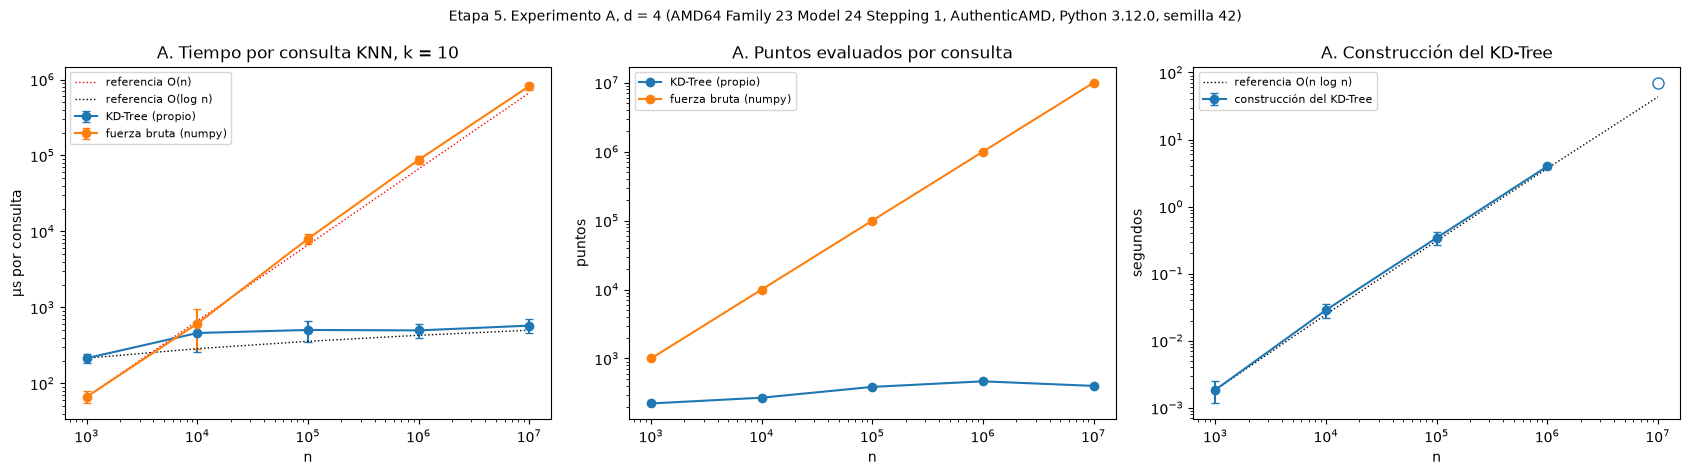

,metodo,pendiente_empirica,esperado,rango
0,KD-Tree (propio),0.09,≈0 (log n),"1,000 a 10,000,000"
1,fuerza bruta (numpy),1.03,≈1 (n),"1,000 a 10,000,000"


,metodo,pendiente_empirica,esperado,rango
0,KD-Tree (propio),1.11,≈1.0-1.1 (n log n),"1,000 a 1,000,000"


In [10]:
kd_consulta = consulta_a[consulta_a["metodo"] == KD]
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.8))
for metodo, datos in consulta_a.groupby("metodo", sort=False):
    ax1.errorbar(datos["n"], datos["us_por_operacion"], yerr=datos["desv_us"], marker="o", capsize=3, label=metodo)
    ax2.plot(datos["n"], datos["puntos_evaluados"], marker="o", label=metodo)
base = consulta_a[consulta_a["metodo"] == FB].iloc[0]
referencia(ax1, TAMANOS_TODOS, base["n"], base["us_por_operacion"], lambda n: n, "r:", "O(n)")
referencia(ax1, TAMANOS_TODOS, kd_consulta["n"].iloc[0], kd_consulta["us_por_operacion"].iloc[0], np.log2, "k:",
           "O(log n)")
repetidas = construccion_a[construccion_a["repeticiones"] > 1]
barras = ax3.errorbar(repetidas["n"], repetidas["promedio_s"], yerr=repetidas["desv_est_s"], marker="o", capsize=3,
                      label="construcción del KD-Tree")
unica = construccion_a[construccion_a["repeticiones"] == 1]
ax3.plot(unica["n"], unica["promedio_s"], marker="o", markerfacecolor="none", markersize=8, linestyle="none",
         color=barras[0].get_color())
base = construccion_a.iloc[0]
referencia(ax3, TAMANOS_TODOS, base["n"], base["promedio_s"], lambda n: n * np.log2(n), "k:", "O(n log n)")
ejes_loglog(ax1, "A. Tiempo por consulta KNN, k = 10", "n", "µs por consulta")
ejes_loglog(ax2, "A. Puntos evaluados por consulta", "n", "puntos")
ejes_loglog(ax3, "A. Construcción del KD-Tree", "n", "segundos")
plt.suptitle(f"Etapa 5. Experimento A, d = 4 ({plataforma_de(tiempos_a)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "knn_n.png", dpi=150)
plt.show()

display(pendientes(consulta_a, "us_por_operacion", {KD: "≈0 (log n)", FB: "≈1 (n)"}))
pendientes(construccion_a, "promedio_s", {KD: "≈1.0-1.1 (n log n)"}, hasta=TAMANOS[-1])

### Experimento B. KNN según la dimensión

Con n = 100 000 puntos uniformes se varía la dimensión entre 2 y 32, con k = 10. Se espera que la fracción de puntos que evalúa el KD-Tree crezca rápido con d. Con d alto, la distancia al vecino más cercano se parece a la distancia a cualquier punto, la poda deja de descartar regiones y el KD-Tree evalúa casi todos los puntos (Weber, Schek y Blott, 1998). Por eso la etapa 7, que trabaja con vectores de dimensión alta, usa búsqueda aproximada y compara con la fuerza bruta.

d =  2 medido
d =  4 medido
d =  8 medido
d = 16 medido
d = 32 medido
Resultados guardados en results/etapa_5/knn_dimension_tiempos.csv


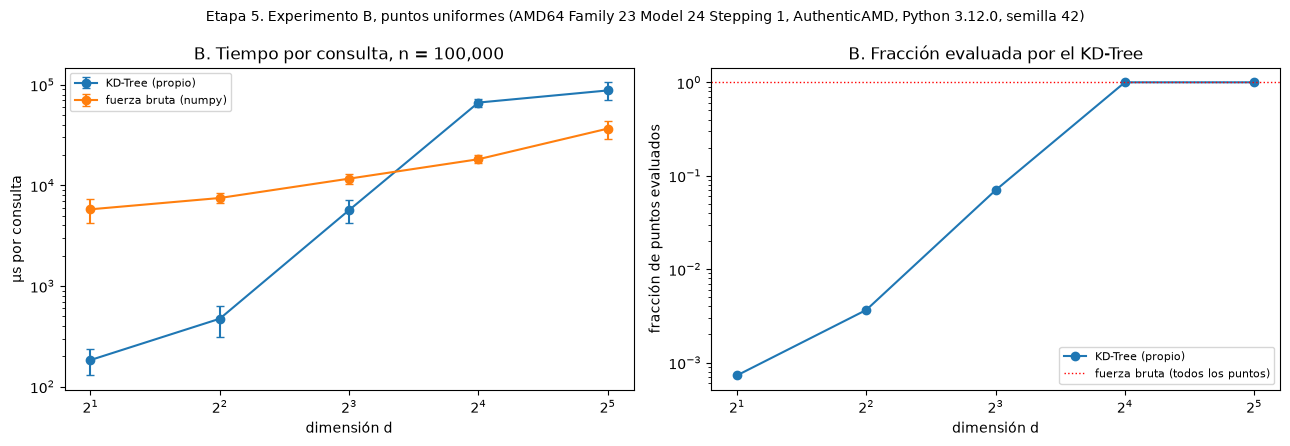

,metodo,d,promedio_s,desv_est_s,us_por_operacion,desv_us,repeticiones,error_rel_media,puntos_evaluados,fraccion_evaluada
0,KD-Tree (propio),2,0.001836,0.000544,183.6,54.4,100,0.0296,73.0,0.0007
1,fuerza bruta (numpy),2,0.057876,0.015382,5787.6,1538.2,100,0.0266,100000.0,1.0000
2,KD-Tree (propio),4,0.004728,0.001641,472.8,164.1,100,0.0347,366.0,0.0037
3,fuerza bruta (numpy),4,0.074989,0.008207,7498.9,820.7,100,0.0109,100000.0,1.0000
4,KD-Tree (propio),8,0.056786,0.014293,5678.6,1429.3,100,0.0252,6999.0,0.0700
5,fuerza bruta (numpy),8,0.116775,0.012695,11677.5,1269.5,100,0.0109,100000.0,1.0000
6,KD-Tree (propio),16,0.666402,0.064409,66640.2,6440.9,100,0.0097,99999.0,1.0000
7,fuerza bruta (numpy),16,0.182127,0.016876,18212.7,1687.6,100,0.0093,100000.0,1.0000
8,KD-Tree (propio),32,0.879631,0.179800,87963.1,17980.0,100,0.0204,100000.0,1.0000
9,fuerza bruta (numpy),32,0.366849,0.074643,36684.9,7464.3,100,0.0203,100000.0,1.0000


In [11]:
DIMENSIONES = [2, 4, 8, 16, 32]
N_DIMENSION = 100_000
BLOQUE = 10


def medir_b():
    filas = []
    for d in DIMENSIONES:
        rng = np.random.default_rng(SEED + d)
        X = rng.uniform(size=(N_DIMENSION, d))
        arbol = KDTree(X)
        verificar(arbol, X, X[rng.integers(0, N_DIMENSION, size=5)], K)
        gc.collect()
        for rep in range(REPETICIONES):
            consultas = X[rng.integers(0, N_DIMENSION, size=BLOQUE)]
            segundos, evaluados = medir(knn_kd, arbol, consultas, K, recolectar=False)
            filas.append({"metodo": KD, "d": d, "repeticion": rep, "operaciones": BLOQUE, "segundos": segundos,
                          "puntos_evaluados": evaluados})
            segundos, _ = medir(knn_fb, X, consultas, K, recolectar=False)
            filas.append({"metodo": FB, "d": d, "repeticion": rep, "operaciones": BLOQUE, "segundos": segundos,
                          "puntos_evaluados": N_DIMENSION})
        del X, arbol
        print(f"d = {d:>2} medido")
    return pd.DataFrame(filas)


tiempos_b = resultados(CARPETA_RESULTADOS / "knn_dimension_tiempos.csv", medir_b)
resumen_b = resumir(tiempos_b, ("metodo", "d")).merge(
    tiempos_b.groupby(["metodo", "d"], as_index=False, sort=False)["puntos_evaluados"].mean(), on=["metodo", "d"])
resumen_b["fraccion_evaluada"] = resumen_b["puntos_evaluados"] / N_DIMENSION

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for metodo, datos in resumen_b.groupby("metodo", sort=False):
    ax1.errorbar(datos["d"], datos["us_por_operacion"], yerr=datos["desv_us"], marker="o", capsize=3, label=metodo)
kd_b = resumen_b[resumen_b["metodo"] == KD]
ax2.plot(kd_b["d"], kd_b["fraccion_evaluada"], marker="o", label=KD)
ax2.axhline(1.0, color="r", ls=":", lw=1, label="fuerza bruta (todos los puntos)")
ax1.set_yscale("log")
ax1.set_ylabel("µs por consulta")
ax1.set_title(f"B. Tiempo por consulta, n = {N_DIMENSION:,}")
ax2.set_yscale("log")
ax2.set_ylabel("fracción de puntos evaluados")
ax2.set_title("B. Fracción evaluada por el KD-Tree")
for ax in (ax1, ax2):
    ax.set_xscale("log", base=2)
    ax.set_xlabel("dimensión d")
    ax.legend(fontsize=8)
plt.suptitle(f"Etapa 5. Experimento B, puntos uniformes ({plataforma_de(tiempos_b)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "knn_dimension.png", dpi=150)
plt.show()

resumen_b.round({"promedio_s": 6, "desv_est_s": 6, "us_por_operacion": 1, "desv_us": 1, "error_rel_media": 4,
                 "puntos_evaluados": 0, "fraccion_evaluada": 4})

### Experimento C. KNN según k

Con n = 1M puntos remuestreados se varía k entre 1 y 1 000. El KD-Tree debe evaluar más puntos a medida que crece k, porque el radio del k-ésimo vecino es mayor y la poda descarta menos. La fuerza bruta calcula siempre las n distancias y solo cambia el costo de seleccionar los k menores.

k =     1 medido
k =    10 medido
k =   100 medido
k = 1,000 medido
Resultados guardados en results/etapa_5/knn_k_tiempos.csv


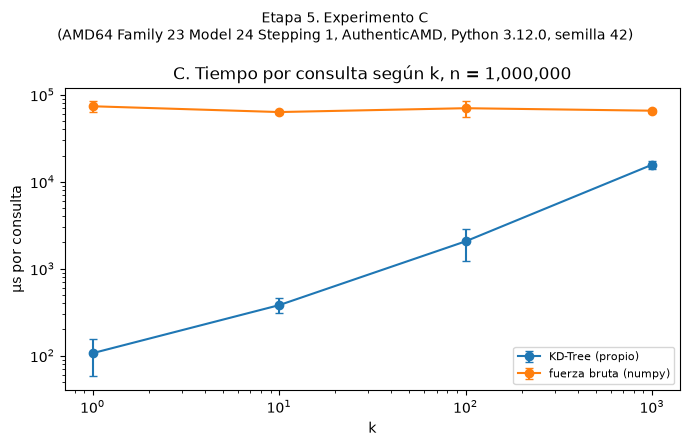

,metodo,k,promedio_s,desv_est_s,us_por_operacion,desv_us,repeticiones,error_rel_media,puntos_evaluados
0,KD-Tree (propio),1,0.001065,0.000488,106.5,48.8,100,0.0458,31.0
1,fuerza bruta (numpy),1,0.737450,0.103066,73745.0,10306.6,100,0.0140,1000000.0
2,KD-Tree (propio),10,0.003799,0.000745,379.9,74.5,100,0.0196,463.0
3,fuerza bruta (numpy),10,0.632499,0.025785,63249.9,2578.5,100,0.0041,1000000.0
4,KD-Tree (propio),100,0.020590,0.008242,2059.0,824.2,100,0.0400,1861.0
5,fuerza bruta (numpy),100,0.700354,0.139685,70035.4,13968.5,100,0.0199,1000000.0
6,KD-Tree (propio),1000,0.156669,0.017744,15666.9,1774.4,100,0.0113,9097.0
7,fuerza bruta (numpy),1000,0.655558,0.037873,65555.8,3787.3,100,0.0058,1000000.0


,metodo,pendiente_empirica,esperado,rango
0,KD-Tree (propio),0.72,creciente con k,"1 a 1,000"
1,fuerza bruta (numpy),-0.01,≈0,"1 a 1,000"


In [12]:
VALORES_K = [1, 10, 100, 1_000]
N_K = 1_000_000


def medir_c():
    filas = []
    X = datos_remuestreados(N_K)
    arbol = KDTree(X)
    rng = np.random.default_rng(SEED)
    for k in VALORES_K:
        verificar(arbol, X, X[rng.integers(0, N_K, size=5)], k)
        gc.collect()
        for rep in range(REPETICIONES):
            consultas = X[rng.integers(0, N_K, size=BLOQUE)]
            segundos, evaluados = medir(knn_kd, arbol, consultas, k, recolectar=False)
            filas.append({"metodo": KD, "k": k, "repeticion": rep, "operaciones": BLOQUE, "segundos": segundos,
                          "puntos_evaluados": evaluados})
            segundos, _ = medir(knn_fb, X, consultas, k, recolectar=False)
            filas.append({"metodo": FB, "k": k, "repeticion": rep, "operaciones": BLOQUE, "segundos": segundos,
                          "puntos_evaluados": N_K})
        print(f"k = {k:>5,} medido")
    del X, arbol
    return pd.DataFrame(filas)


tiempos_c = resultados(CARPETA_RESULTADOS / "knn_k_tiempos.csv", medir_c)
resumen_c = resumir(tiempos_c, ("metodo", "k")).merge(
    tiempos_c.groupby(["metodo", "k"], as_index=False, sort=False)["puntos_evaluados"].mean(), on=["metodo", "k"])

fig, ax = plt.subplots(figsize=(7, 4.5))
for metodo, datos in resumen_c.groupby("metodo", sort=False):
    ax.errorbar(datos["k"], datos["us_por_operacion"], yerr=datos["desv_us"], marker="o", capsize=3, label=metodo)
ejes_loglog(ax, f"C. Tiempo por consulta según k, n = {N_K:,}", "k", "µs por consulta")
plt.suptitle(f"Etapa 5. Experimento C\n({plataforma_de(tiempos_c)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "knn_k.png", dpi=150)
plt.show()

display(resumen_c.round({"promedio_s": 6, "desv_est_s": 6, "us_por_operacion": 1, "desv_us": 1,
                         "error_rel_media": 4, "puntos_evaluados": 0}))
pendientes(resumen_c, "us_por_operacion", {KD: "creciente con k", FB: "≈0"}, x="k")

### Experimento D. Consultas sobre el índice real

Se comparan las dos variantes exactas de dos consultas del paso 5, sobre el índice real de 336 415 productos.

- **Vecinos dentro de la categoría.** Con el filtro por categoría sobre el árbol global y con el árbol de la categoría, para bloques de 10 productos elegidos al azar y k = 10. Justifica construir un árbol por categoría.
- **Rango multidimensional.** La caja del paso 5 con el KD-Tree y con el rango de precio del B+Tree de la etapa 4 más el filtro por los otros dos atributos. Cada repetición es una consulta. Justifica el índice multidimensional frente al índice de una sola clave.

In [13]:
CATEGORIA_FILTRO, CATEGORIA_ARBOL = "filtro sobre el árbol global", "árbol de la categoría"
RANGO_KD, RANGO_BMAS = "KD-Tree", "B+Tree de la etapa 4 + filtro"


def vecinos_con_filtro(productos):
    for i in productos:
        kd.knn(indice.Z[i], K, etiqueta=int(indice.categoria[i]))


def vecinos_con_arbol_de_categoria(productos):
    for i in productos:
        indice.kd_categoria[int(indice.categoria[i])].knn(indice.Z[i], K)


def medir_d():
    filas = []
    rng = np.random.default_rng(SEED)
    gc.collect()
    for rep in range(REPETICIONES):
        productos = rng.choice(kd.n, size=BLOQUE, replace=False)
        for metodo, funcion in [(CATEGORIA_FILTRO, vecinos_con_filtro), (CATEGORIA_ARBOL, vecinos_con_arbol_de_categoria)]:
            segundos, _ = medir(funcion, productos, recolectar=False)
            filas.append({"consulta": "vecinos en la categoría", "metodo": metodo, "repeticion": rep,
                          "operaciones": BLOQUE, "segundos": segundos})
    for rep in range(REPETICIONES):
        segundos, _ = medir(kd.rango, MINIMOS, MAXIMOS, recolectar=False)
        filas.append({"consulta": "rango multidimensional", "metodo": RANGO_KD, "repeticion": rep, "operaciones": 1,
                      "segundos": segundos})
        segundos, _ = medir(rango_bmas_con_filtro, recolectar=False)
        filas.append({"consulta": "rango multidimensional", "metodo": RANGO_BMAS, "repeticion": rep,
                      "operaciones": 1, "segundos": segundos})
    return pd.DataFrame(filas)


tiempos_d = resultados(CARPETA_RESULTADOS / "indice_real_tiempos.csv", medir_d)
resumen_d = resumir(tiempos_d, ("consulta", "metodo"))
resumen_d["ms_por_operacion"] = resumen_d["us_por_operacion"] / 1e3
resumen_d["desv_ms"] = resumen_d["desv_us"] / 1e3
for consulta, datos in resumen_d.groupby("consulta", sort=False):
    lento, rapido = datos["ms_por_operacion"].max(), datos["ms_por_operacion"].min()
    print(f"{consulta}: la variante más rápida tarda {lento / rapido:.0f} veces menos")
resumen_d[["consulta", "metodo", "ms_por_operacion", "desv_ms", "error_rel_media", "repeticiones"]].round(
    {"ms_por_operacion": 3, "desv_ms": 3, "error_rel_media": 4})

Resultados guardados en results/etapa_5/indice_real_tiempos.csv
vecinos en la categoría: la variante más rápida tarda 55 veces menos
rango multidimensional: la variante más rápida tarda 50 veces menos


,consulta,metodo,ms_por_operacion,desv_ms,error_rel_media,repeticiones
0,vecinos en la categoría,filtro sobre el árbol global,14.837,9.241,0.0623,100
1,vecinos en la categoría,árbol de la categoría,0.269,0.060,0.0221,100
2,rango multidimensional,KD-Tree,6.759,1.291,0.0191,100
3,rango multidimensional,B+Tree de la etapa 4 + filtro,338.075,39.538,0.0117,100


### Memoria actual y pico

Se mide con `tracemalloc` de 1K a 10M puntos remuestreados, sin contar la matriz original.

- **Construcción del KD-Tree.** La memoria actual es la del árbol: la copia reordenada de los puntos, la permutación y las listas de nodos. La pico incluye las copias temporales de numpy durante la construcción.
- **Consulta del KD-Tree.** Una consulta KNN con k = 10. Solo crea los arreglos de las hojas visitadas y el heap de candidatos.
- **Consulta de la fuerza bruta.** Una consulta KNN con k = 10. No guarda ninguna estructura, pero crea arreglos temporales con las n diferencias y las n distancias, así que su pico es O(n·d).

n =      1,000 medido
n =     10,000 medido
n =    100,000 medido
n =  1,000,000 medido
n = 10,000,000 medido
Resultados guardados en results/etapa_5/memoria.csv


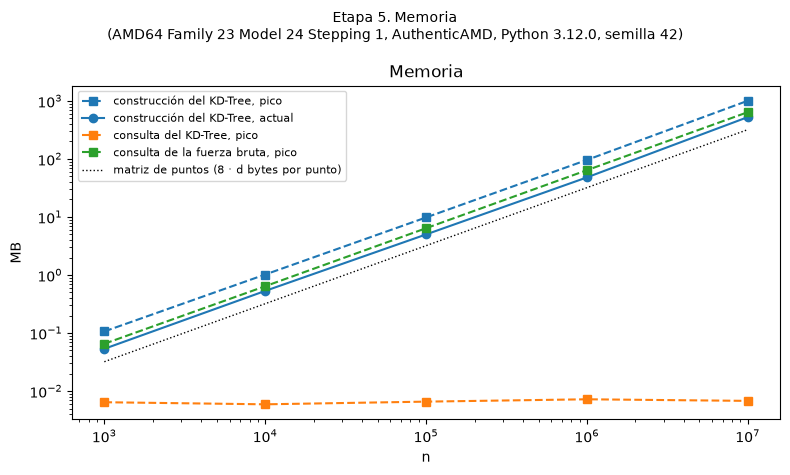

actual_mb                              \
metodo   construcción del KD-Tree consulta de la fuerza bruta   
n                                                               
1000                        0.053                       0.002   
10000                       0.532                       0.002   
100000                      4.998                       0.002   
1000000                    48.096                       0.002   
10000000                  526.195                       0.003   

                                               pico_mb  \
metodo   consulta del KD-Tree construcción del KD-Tree   
n                                                        
1000                    0.004                    0.106   
10000                   0.004                    1.019   
100000                  0.004                    9.806   
1000000                 0.004                   96.105   
10000000                0.004                 1006.206   

                                                           \
metodo   consulta de la fuerza bruta consulta del KD-Tree   
n                                                           
1000                           0.065                0.006   
10000                          0.640                0.006   
100000                         6.400                0.007   
1000000                       64.000                0.007   
10000000                     640.000                0.007   

             bytes_por_punto_pico                              \
metodo   construcción del KD-Tree consulta de la fuerza bruta   
n                                                               
1000                      106.440                      65.256   
10000                     101.888                      64.030   
100000                     98.060                      64.003   
1000000                    96.105                      64.000   
10000000                  100.621                      64.000   

                               
metodo   consulta del KD-Tree  
n                              
1000                    6.416  
10000                   0.590  
100000                  0.066  
1000000                 0.007  
10000000                0.001

In [14]:
def medir_memoria_5():
    filas = []
    for n in TAMANOS_TODOS:
        X = datos_remuestreados(n)
        arbol, actual, pico = medir_memoria(KDTree, X)
        filas.append({"metodo": "construcción del KD-Tree", "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6,
                      "matriz_mb": X.nbytes / 1e6})
        _, actual, pico = medir_memoria(arbol.knn, X[0], K)
        filas.append({"metodo": "consulta del KD-Tree", "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6,
                      "matriz_mb": X.nbytes / 1e6})
        _, actual, pico = medir_memoria(knn_fuerza_bruta, X, X[0], K)
        filas.append({"metodo": "consulta de la fuerza bruta", "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6,
                      "matriz_mb": X.nbytes / 1e6})
        del X, arbol
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


memoria = resultados(CARPETA_RESULTADOS / "memoria.csv", medir_memoria_5)
memoria["bytes_por_punto_actual"] = memoria["actual_mb"] * 1e6 / memoria["n"]
memoria["bytes_por_punto_pico"] = memoria["pico_mb"] * 1e6 / memoria["n"]

fig, ax = plt.subplots(figsize=(8, 4.8))
for metodo, datos in memoria.groupby("metodo", sort=False):
    linea = ax.plot(datos["n"], datos["pico_mb"], marker="s", linestyle="--", label=f"{metodo}, pico")
    if metodo.startswith("construcción"):
        ax.plot(datos["n"], datos["actual_mb"], marker="o", color=linea[0].get_color(), label=f"{metodo}, actual")
matriz = memoria[memoria["metodo"] == "construcción del KD-Tree"]
ax.plot(matriz["n"], matriz["matriz_mb"], "k:", lw=1, label="matriz de puntos (8 · d bytes por punto)")
ejes_loglog(ax, "Memoria", "n", "MB")
plt.suptitle(f"Etapa 5. Memoria\n({plataforma_de(memoria)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "memoria.png", dpi=150)
plt.show()

memoria.pivot(index="n", columns="metodo", values=["actual_mb", "pico_mb", "bytes_por_punto_pico"]).round(3)

### Verificación del protocolo

La celda comprueba que cada medición de tiempo guardada tiene las repeticiones del diseño. Son 100 en todas las consultas y las de `REPETICIONES_CONSTRUCCION` en la construcción del KD-Tree.

In [15]:
def comprobar(tabla, columnas, esperado):
    """Cada combinación tiene el número de repeticiones que indica esperado(fila)."""
    for clave_grupo, repeticiones in tabla.groupby(columnas)["segundos"].count().items():
        fila = dict(zip(columnas, clave_grupo if isinstance(clave_grupo, tuple) else (clave_grupo,)))
        assert repeticiones == esperado(fila), f"{fila}: {repeticiones} repeticiones, se esperaban {esperado(fila)}"


comprobar(tiempos_a, ["operacion", "metodo", "n"],
          lambda f: REPETICIONES_CONSTRUCCION[f["n"]] if f["operacion"] == "construccion" else REPETICIONES)
comprobar(tiempos_b, ["metodo", "d"], lambda f: REPETICIONES)
comprobar(tiempos_c, ["metodo", "k"], lambda f: REPETICIONES)
comprobar(tiempos_d, ["consulta", "metodo"], lambda f: REPETICIONES)
print("Las consultas tienen 100 repeticiones en todos los tamaños y la construcción del KD-Tree tiene las de "
      "REPETICIONES_CONSTRUCCION.")

Las consultas tienen 100 repeticiones en todos los tamaños y la construcción del KD-Tree tiene las de REPETICIONES_CONSTRUCCION.


### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/etapa_5/`, con la plataforma del paso 1. Los vectores, la altura y los nodos de los árboles, los vecinos, los puntos evaluados y la memoria dependen solo de los datos y de la semilla. Una ejecución anterior de este notebook en otra máquina (Intel64 Family 6 Model 186, Python 3.12.10) obtuvo los mismos valores sobre el índice real. Entre ellos están los 336 415 vectores de 607 categorías con las mismas medias y desviaciones, el KD-Tree de 32 737 nodos y altura 15, los vecinos del producto de ejemplo con 181 y 315 puntos evaluados, ninguna diferencia en las 3 000 consultas de la verificación, los 4 195 productos de la caja con 8 700 puntos evaluados, los 100 715 productos del rango de precio y los vecinos de los 193 422 productos con estado. Los árboles de 1K a 1M del experimento A tienen los mismos nodos que en aquella ejecución, y su memoria difiere en 2 KB como máximo. Los puntos evaluados de los experimentos A, B y C son promedios sobre consultas sorteadas con la semilla. Esta versión sortea más consultas que la anterior, así que esos promedios difieren de los de aquella en menos de 5 %. Los tiempos absolutos cambian con la máquina.

- **Vectores.** El precio va de 0.01 a 30 499 dólares, y en escala logarítmica su desviación es 0.96. La desviación de `log_rating_number` (1.87) es 2.8 veces la de `average_rating` (0.67), así que sin el z-score dominaría la distancia. 193 416 productos tienen vistas, carritos o compras en el stream y 193 422 tienen estado en la etapa 3. Los 6 de diferencia solo recibieron reseñas o devoluciones.
- **Índice.** El KD-Tree global tiene 32 737 nodos y altura 15, que es ⌈log₂(n / 32)⌉ + 1, la altura de un árbol balanceado con hojas de hasta 32 puntos. El índice con los 607 árboles por categoría se construye en 2.8 s y ocupa 70.9 MB, 211 bytes por producto. Guarda dos juegos de árboles, el global y los de las categorías, además de los vectores normalizados y la tabla hash de posiciones.
- **Consultas del paso 5.** Los 5 vecinos de la impresora HP DeskJet 2755e dentro de su categoría son otras impresoras HP con calificación de 4.1 o 4.2, y su árbol evalúa 181 de los 321 puntos de la categoría. En todo el catálogo el KD-Tree evalúa 315 de 336 415 puntos (0.09 %), y los vecinos son de otras categorías, como trituradoras o rotuladoras, con precio, calificación y popularidad parecidos. Por eso la recomendación usa el árbol de la categoría. En la caja de precio entre 10 y 20 dólares, calificación de al menos 4.5 y al menos 1 000 calificaciones hay 4 195 productos. El KD-Tree los encuentra evaluando 8 700 puntos, el 2.6 % del índice. El B+Tree de la etapa 4 devuelve los 100 715 productos del rango de precio, y el filtro descarta el 95.8 %.
- **A, consulta.** La fuerza bruta tiene pendiente 1.03, como O(n·d), y cuesta entre 61 y 88 ns por punto. El KD-Tree tiene pendiente 0.09. De 1K a 10M, n crece 10 000 veces y su tiempo por consulta 2.7 veces, de 215 a 577 µs, mientras la fracción evaluada baja de 22 % a 0.004 %. Con 1K la fuerza bruta es 3.2 veces más rápida, porque una operación de numpy sobre 1 000 puntos cuesta menos que recorrer el árbol en Python. Desde 10K el KD-Tree es más rápido, 1.3 veces con 10K, 176 con 1M y 1 418 con 10M (0.58 frente a 817 ms).
- **A, hojas visitadas.** El tiempo del KD-Tree no crece de forma pareja porque depende de las hojas que visita. El árbol divide por la mediana hasta dejar 32 puntos o menos, así que sus hojas tienen n / 2^(altura − 1) puntos, entre 19.1 con 10M y 31.3 con 1K. Al dividir los puntos evaluados por ese tamaño, el KD-Tree visita unas 7 hojas por consulta con 1K, 14 con 10K, 15 a 16 con 100K y 1M y 21 con 10M. El tiempo sigue esa cuenta, entre 27 y 34 µs por hoja visitada, que incluyen los nodos internos recorridos para llegar a ella. Por eso se duplica de 1K a 10K y casi no cambia de 100K a 1M.
- **A, construcción.** La pendiente de 1K a 1M es 1.11, como O(n log n). El costo por punto pasa de 1.9 a 4.0 µs, el doble, igual que log₂ n, que pasa de 10 a 20. Con 1M una repetición tarda 4.0 s, así que 100 tomarían 6.6 min, y con 30 el error relativo de la media es 1.4 %. Con 10M la única corrida tarda 70.4 s y 100 tomarían casi 2 h. Ese tiempo es 17.7 veces el de 1M, más que las 11.7 veces de n log n. La causa es el número de nodos. Con 10M, 2^18 hojas tendrían 38 puntos, más que el tamaño de hoja, así que el árbol necesita un nivel más y pasa de 65 535 a 1 048 575 nodos, 16 veces más. Cada nodo cuesta una llamada recursiva en Python, unos 61 µs con 1M y 67 µs con 10M.
- **B.** Con puntos uniformes y n = 100K, la fracción que evalúa el KD-Tree pasa de 0.07 % con d = 2 a 0.37 % con d = 4 y 7 % con d = 8, y desde d = 16 evalúa prácticamente todos los puntos. Hasta d = 8 el KD-Tree es más rápido que la fuerza bruta, 31.5 veces con d = 2, 15.9 con d = 4 y 2.1 con d = 8. Con d = 16 y d = 32 es 3.7 y 2.4 veces más lento, porque recorre todas las hojas en Python sin descartar ninguna, mientras la fuerza bruta hace el mismo cálculo en una operación de numpy. Coincide con la regla práctica de que el KD-Tree poda bien solo si n es mucho mayor que 2^d. Con d = 16, 2^16 = 65 536 ya es del orden de n. El tiempo de la fuerza bruta crece con d, de 5.8 a 36.7 ms. Por eso la etapa 7, con vectores de dimensión alta, usa búsqueda aproximada y toma la fuerza bruta como referencia exacta.
- **C.** Con n = 1M, los puntos que evalúa el KD-Tree crecen de 31 con k = 1 a 9 097 con k = 1 000, y su tiempo de 106 µs a 15.7 ms, con pendiente 0.72. De k = 10 a k = 1 000 los puntos crecen 19.6 veces y el tiempo 41 veces, porque cada candidato que entra al `MinHeap` de k elementos cuesta O(log k) en Python. El costo por punto evaluado sube de 0.82 a 1.72 µs. La fuerza bruta tiene pendiente −0.01, porque calcula siempre las n distancias y elige los k menores con `np.argpartition` en O(n). Con k = 10 el KD-Tree es 167 veces más rápido y con k = 1 000 todavía 4.2 veces.
- **A y C, misma configuración.** n = 1M con k = 10 se mide en los dos experimentos con los mismos datos y el mismo árbol, y los puntos evaluados son casi iguales (466 y 463). Los tiempos difieren, 499 frente a 380 µs para el KD-Tree y 87.6 frente a 63.2 ms para la fuerza bruta. La diferencia, de 31 % y 38 %, supera el error relativo de las medias, que es 2 % o menos, así que no viene del muestreo. Se atribuye a las condiciones de la máquina durante cada experimento, como la frecuencia del procesador o los otros procesos. Por eso las conclusiones comparan los métodos dentro de un mismo experimento, donde se miden intercalados.
- **D.** En el índice real, los 10 vecinos dentro de la categoría tardan 0.27 ms con el árbol de la categoría y 14.8 ms con el filtro sobre el árbol global, 55 veces más. El filtro también varía más, con una desviación de 9.2 ms, porque para una categoría pequeña recorre muchas hojas del árbol global hasta reunir 10 productos de ella. El rango de la caja tarda 6.8 ms con el KD-Tree y 338 ms con el B+Tree más el filtro, 50 veces más. El B+Tree devuelve los 100 715 productos del rango de precio, 11.6 veces los 8 700 puntos que evalúa el KD-Tree, y para cada uno se busca su posición en la tabla hash y se comparan dos atributos en Python. El KD-Tree filtra cada hoja con una operación de numpy. Las dos comparaciones justifican los árboles por categoría y el índice multidimensional frente al índice de una sola clave.
- **Precisión.** Las consultas tienen 100 repeticiones en todos los tamaños, incluido 10M, y su error relativo de la media es de 6.2 % como máximo, en el filtro sobre el árbol global del experimento D. En la construcción es de 3.7 % como máximo.
- **Memoria.** El KD-Tree ocupa unos 40 bytes por punto, 32 de la copia reordenada de los puntos y 8 de la permutación, más unos 115 bytes por nodo en las listas de nodos. Por eso los bytes por punto siguen a los nodos por punto, con 48.1 con 1M y 52.6 con 10M, y el árbol llega a 526 MB con 10M. El pico de la construcción es de unos 100 bytes por punto, el doble del árbol, por las copias temporales de numpy al dividir cada nodo, y con 10M llega a 1 006 MB. El pico de una consulta del KD-Tree es de unos 7 KB en todos los tamaños, porque solo crea los arreglos de las hojas visitadas y el heap de k candidatos. Una consulta de la fuerza bruta no deja memoria ocupada, pero su pico es exactamente 64 bytes por punto, dos arreglos temporales de n × d valores de 8 bytes con las diferencias y sus cuadrados. Con 10M son 640 MB, unas 94 000 veces el pico de la consulta del KD-Tree.

El KD-Tree cumple las complejidades teóricas en dimensión baja. La consulta KNN crece como O(log n), con pendiente 0.09 frente a 1.03 de la fuerza bruta, y su costo sigue a las hojas visitadas. La construcción es O(n log n) y la memoria O(n), con unos 50 bytes por punto. Con k grande la ventaja baja, pero se mantiene hasta k = 1 000. Con dimensión alta desaparece, porque desde d = 16 la poda no descarta nada y la fuerza bruta es más rápida. Con los 4 atributos del escenario, el índice responde los productos similares en menos de 1 ms, 0.41 ms por consulta en el paso 7, y el rango multidimensional 50 veces más rápido que el índice de precios de la etapa 4.

## Paso 7. Salida de la etapa 5

La etapa produce dos archivos en `data/interim/<CATEGORIA>/etapa_5/`.

| Archivo | Contenido | Etapas que lo usan |
| --- | --- | --- |
| `vectores.npz` | `parent_asin`, vectores normalizados, media y desviación de cada atributo, categoría de cada producto | 9 (productos similares en línea con `IndiceProductos`, uso previsto) |
| `vecinos.parquet` | Los 10 vecinos exactos de cada producto con estado en la etapa 3, en todo el catálogo y dentro de su categoría | 9 (productos relacionados, uso previsto) |

La etapa 7 no usa estos vectores de 4 dimensiones. Construye sus propios vectores de dimensión alta y usa `knn_fuerza_bruta` de `src/etapa_5/kdtree.py` como referencia exacta para medir el recall@K de su búsqueda aproximada. Las etapas siguientes también pueden importar `IndiceProductos` para consultar vecinos en línea.

Los vecinos se calculan una vez para los productos del índice con estado en la etapa 3, porque es la operación de la etapa sobre el catálogo completo. El tiempo por consulta con repeticiones está en el experimento D.

In [16]:
arbol_precio.cerrar()
np.savez_compressed(RUTA_VECTORES, asins=np.array(indice.asins), Z=indice.Z, media=indice.media, desv=indice.desv,
                    atributos=np.array(ATRIBUTOS), categoria=indice.categoria,
                    nombres_categoria=np.array(indice.nombres_categoria))

activos = [a for a in estados["parent_asin"] if indice.posicion.obtener(a) is not None]
filas = []
t0 = time.perf_counter()
for asin in activos:
    for alcance, misma in (("global", False), ("misma_categoria", True)):
        for rango, (distancia, vecino) in enumerate(indice.similares(asin, k=10, misma_categoria=misma), start=1):
            filas.append({"parent_asin": asin, "alcance": alcance, "rango": rango, "vecino": vecino,
                          "distancia": distancia})
t_vecinos = time.perf_counter() - t0
vecinos = pd.DataFrame(filas)
pq.write_table(pa.Table.from_pandas(vecinos, preserve_index=False), RUTA_VECINOS, compression="zstd")
assert len(activos) == len(con_estado)

print(f"Vecinos calculados para {len(activos):,} productos con estado en la etapa 3 en {t_vecinos:.1f} s "
      f"({t_vecinos / (2 * len(activos)) * 1e3:.2f} ms por consulta)")
for ruta in (RUTA_VECTORES, RUTA_VECINOS):
    print(f"{ruta_relativa(ruta)}: {ruta.stat().st_size / 1e6:,.1f} MB")
vecinos.head(12)

Vecinos calculados para 193,422 productos con estado en la etapa 3 en 159.4 s (0.41 ms por consulta)
data/interim/Office_Products/etapa_5/vectores.npz: 5.4 MB
data/interim/Office_Products/etapa_5/vecinos.parquet: 52.5 MB


,parent_asin,alcance,rango,vecino,distancia
0,B00LRUXN42,global,1,B0BWXX6J6C,0.053327
1,B00LRUXN42,global,2,B01HQPKQSM,0.067548
2,B00LRUXN42,global,3,B0C6QG9Q71,0.081423
3,B00LRUXN42,global,4,B006BYRJ4Y,0.087434
4,B00LRUXN42,global,5,B004E2OHUE,0.087485
5,B00LRUXN42,global,6,B08ZLPRJQL,0.092431
6,B00LRUXN42,global,7,B07WXMM57L,0.094621
7,B00LRUXN42,global,8,1469393352,0.094765
8,B00LRUXN42,global,9,B071RVNC4K,0.101138
9,B00LRUXN42,global,10,B0971PBWCD,0.106255


## Resumen de la etapa 5

| Aspecto | Decisión |
| --- | --- |
| Estructura | KD-Tree propio con corte por la mediana de la dimensión de mayor dispersión y hojas de hasta 32 puntos |
| Por qué KD-Tree | Puntos (no objetos con extensión), dimensión baja (d = 4) y conjunto casi estático |
| Vectores | log del precio, calificación, log del número de calificaciones y log de la actividad en el stream, normalizados con z-score |
| Entrada | Recorrido del B+Tree de la etapa 4, catálogo y estado del stream de la etapa 3 |
| Consultas | KNN exacto global y dentro de la categoría con un KD-Tree por categoría (k mejores en el `MinHeap` de la etapa 2) y rango multidimensional |
| Línea base | KNN por fuerza bruta con numpy, que también es la referencia exacta de la etapa 7 |
| Salida | Vectores y 10 vecinos exactos por producto con estado en `data/interim/<CATEGORIA>/etapa_5/` |

Referencias. Bentley, J. L. (1975). Multidimensional binary search trees used for associative searching. *Communications of the ACM*, 18(9), 509-517. Friedman, J. H., Bentley, J. L., y Finkel, R. A. (1977). An algorithm for finding best matches in logarithmic expected time. *ACM Transactions on Mathematical Software*, 3(3), 209-226. Guttman, A. (1984). R-trees: A dynamic index structure for spatial searching. *Proceedings of ACM SIGMOD*, 47-57. Weber, R., Schek, H.-J., y Blott, S. (1998). A quantitative analysis and performance study for similarity-search methods in high-dimensional spaces. *Proceedings of VLDB*, 194-205. Samet, H. (2006). *Foundations of Multidimensional and Metric Data Structures*. Morgan Kaufmann.